# Tarea 2 – Regresión Ridge: sobreajuste, `MyRidge` y Ridge vs. Lasso

**Dataset:** Superconductivity Data (Kaggle, `hamidmieh/superconductivity-data`)  
**Variable objetivo:** `critical_temp` (temperatura crítica de superconductores, continua)  
**Muestras:** 21 263  |  **Features predictoras:** 81 (todas cuantitativas)  
**Nota:** El mismo split (`train_size=150`, `test_size=resto`, `random_state=42`) se reutiliza en todos los puntos para que los resultados sean comparables.

> Fuente: https://www.kaggle.com/datasets/hamidmieh/superconductivity-data


In [1]:
import sys
import os

# Carpeta src/ contiene la implementacion propia de MyRidge (Punto 2)
sys.path.insert(0, os.path.join(os.getcwd(), 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from my_ridge import MyRidge

SEMILLA = 42
np.random.seed(SEMILLA)

try:
    plt.style.use('seaborn-v0_8-whitegrid')
except Exception:
    pass
plt.rcParams['figure.dpi'] = 100

print('Entorno listo: numpy', np.__version__, '| scikit-learn', Ridge.__module__.split('.')[0])


Entorno listo: numpy 2.5.4 | scikit-learn sklearn


---
## Punto 1 – Regresión lineal con sobreajuste

**EDA y limpieza:** se inspeccionan dimensiones, tipos, valores faltantes, duplicados y la distribución de la variable objetivo. Como el dataset no tiene faltantes ni columnas no numéricas, la limpieza se limita a verificar eso y conservar únicamente las 81 features cuantitativas.

**Sobreajuste:** se usa un conjunto de entrenamiento deliberadamente pequeño (150 muestras) con 81 predictores, de modo que `LinearRegression` de sklearn sobreajuste. Se reportan RMSE de entrenamiento y de prueba.


In [2]:
# Carga del dataset
ruta_csv = os.path.join('csv', 'train.csv')
df = pd.read_csv(ruta_csv)

columna_objetivo = 'critical_temp'
nombre_features = [col for col in df.columns if col != columna_objetivo]

X = df[nombre_features].values
y = df[columna_objetivo].values

print(f'Dimensiones del dataset: {df.shape}')
print(f'Numero de features cuantitativas: {len(nombre_features)}')
print(f'Variable objetivo: {columna_objetivo!r}')
print(f'Tipos de datos: {df.dtypes.value_counts().to_dict()}')


Dimensiones del dataset: (21263, 82)
Numero de features cuantitativas: 81
Variable objetivo: 'critical_temp'
Tipos de datos: {dtype('float64'): 79, dtype('int64'): 3}


In [3]:
# Analisis exploratorio breve
print('Valores faltantes por columna (total):', int(df.isna().sum().sum()))
print('Filas duplicadas:', int(df.duplicated().sum()))
print()
print('Estadisticas de la variable objetivo:')
print(df[columna_objetivo].describe())
print()
corr = df[nombre_features + [columna_objetivo]].corr()[columna_objetivo].drop(columna_objetivo).abs().sort_values(ascending=False)
print('Top 10 features por correlacion absoluta con el objetivo:')
print(corr.head(10))


Valores faltantes por columna (total): 0
Filas duplicadas: 66

Estadisticas de la variable objetivo:
count    21263.000000
mean        34.421219
std         34.254362
min          0.000210
25%          5.365000
50%         20.000000
75%         63.000000
max        185.000000
Name: critical_temp, dtype: float64

Top 10 features por correlacion absoluta con el objetivo:
wtd_std_ThermalConductivity    0.721271
range_ThermalConductivity      0.687654
range_atomic_radius            0.653759
std_ThermalConductivity        0.653632
wtd_mean_Valence               0.632401
wtd_entropy_atomic_mass        0.626930
wtd_gmean_Valence              0.615653
wtd_entropy_atomic_radius      0.603494
number_of_elements             0.601069
range_fie                      0.600790
Name: critical_temp, dtype: float64


#### Limpieza
- No hay valores faltantes (`isna().sum().sum() == 0`).
- Todas las columnas son numéricas (cuantitativas).
- No se eliminan filas: el dataset es real y se usa completo.


In [4]:
# Split train / test (entrenamiento pequeno para forzar sobreajuste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    train_size=150,
    random_state=SEMILLA,
    shuffle=True
)

print(f'Entrenamiento: {X_train.shape[0]} muestras, {X_train.shape[1]} features')
print(f'Prueba       : {X_test.shape[0]} muestras')


Entrenamiento: 150 muestras, 81 features
Prueba       : 21113 muestras


In [5]:
# Regresion lineal (sklearn) -> sobreajuste esperado
reg_lineal = LinearRegression()
reg_lineal.fit(X_train, y_train)

rmse_lineal_train = float(np.sqrt(mean_squared_error(y_train, reg_lineal.predict(X_train))))
rmse_lineal_test  = float(np.sqrt(mean_squared_error(y_test,  reg_lineal.predict(X_test))))

print('Regresion Lineal (Punto 1):')
print(f'  RMSE entrenamiento : {rmse_lineal_train:.4f}')
print(f'  RMSE prueba        : {rmse_lineal_test:.4f}')
print(f'  R2 entrenamiento   : {reg_lineal.score(X_train, y_train):.4f}')
print(f'  R2 prueba          : {reg_lineal.score(X_test, y_test):.4f}')
print(f'  Brecha (test-train): {rmse_lineal_test - rmse_lineal_train:.4f}')


Regresion Lineal (Punto 1):
  RMSE entrenamiento : 12.6968
  RMSE prueba        : 39.0675
  R2 entrenamiento   : 0.8635
  R2 prueba          : -0.3009
  Brecha (test-train): 26.3707


**Conclusión Punto 1:** con 150 muestras y 81 predictores, el error de entrenamiento es mucho menor que el de prueba (brecha grande), lo que confirma el **sobreajuste** de la regresión lineal no regularizada.


---
## Punto 2 – Implementación de `MyRidge`

Clase `MyRidge(alpha)` en `src/my_ridge.py` (sólo `numpy`):

- `fit(X, y)`: guarda `X_mean_` y `y_mean_` de los datos de `fit`, centra, resuelve  
  $(X_c^T X_c + \lambda I)	heta = X_c^T y_c$ con `np.linalg.solve` (sin columna de unos), y recupera  
  $	heta_0 = ar{y} - ar{x}^T 	heta$.
- `predict(X)`: usa siempre las medias guardadas en `fit`.
- `score(X, y)`: $R^2$ igual que sklearn.
- `rmse(X, y)`: RMSE de las predicciones.
- Atributos sklearn-style: `coef_`, `intercept_`, `X_mean_`, `y_mean_`.

El intercepto no se penaliza (la matriz de diseño no lleva columna de unas).


In [6]:
# Demostracion rapida de MyRidge sobre los datos de entrenamiento (crudos)
modelo_demo = MyRidge(alpha=1.0)
modelo_demo.fit(X_train, y_train)

pred_train = modelo_demo.predict(X_train)
print('coef_  :', np.round(modelo_demo.coef_[:5], 4), '... (primeros 5 de', len(modelo_demo.coef_), ')')
print('intercept_:', round(float(modelo_demo.intercept_), 4))
print('X_mean_ shape:', modelo_demo.X_mean_.shape, '| y_mean_:', round(float(modelo_demo.y_mean_), 4))
print(f'score (R2)  : {modelo_demo.score(X_train, y_train):.4f}')
print(f'rmse        : {modelo_demo.rmse(X_train, y_train):.4f}')
print(f'rmse (test) : {modelo_demo.rmse(X_test, y_test):.4f}')


coef_  : [ 7.7623  2.8488 -5.2825 -2.0456  3.9315] ... (primeros 5 de 81 )
intercept_: -4.4109
X_mean_ shape: (81,) | y_mean_: 33.8714
score (R2)  : 0.8335
rmse        : 14.0232
rmse (test) : 31.9177


---
## Punto 3 – Corregir el sobreajuste con `MyRidge` (Ridge)

Pasos:
1. Estandarizar features con `StandardScaler` **ajustado sólo en train** (sin fuga de datos).
2. Elegir $\lambda$ por validación cruzada k-fold (k=5) sobre `np.logspace(-4, 4, 50)`, re-estandarizando dentro de cada fold.
3. Graficar RMSE de entrenamiento y validación vs $\lambda$ (escala log).
4. Reentrenar con $\lambda^*$ sobre todo train y evaluar el RMSE de prueba **una sola vez**.
5. Comparar con la regresión lineal del Punto 1 y verificar con `sklearn.Ridge` (`np.allclose`) tanto con features estandarizadas como sin estandarizar.


In [7]:
# 3.1 Estandarizacion (fit solo en train)
escalador = StandardScaler()
X_train_std = escalador.fit_transform(X_train)
X_test_std  = escalador.transform(X_test)

print(f'Media X_train_std: {X_train_std.mean(axis=0).mean():.2e} (aprox 0)')
print(f'Std  X_train_std : {X_train_std.std(axis=0).mean():.4f} (aprox 1)')
print(f'Media X_test_std : {X_test_std.mean(axis=0).mean():.4f}')


Media X_train_std: -2.99e-17 (aprox 0)
Std  X_train_std : 1.0000 (aprox 1)
Media X_test_std : -0.0185


In [8]:
# 3.2 Seleccion de lambda* por validacion cruzada k-fold (k=5)
lambdas = np.logspace(-4, 4, 50)
kf = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

rmse_cv_train = np.zeros(len(lambdas))
rmse_cv_val   = np.zeros(len(lambdas))

for i, lam in enumerate(lambdas):
    rmse_train_folds, rmse_val_folds = [], []
    for idx_tr, idx_vl in kf.split(X_train_std):
        X_fold_tr, y_fold_tr = X_train_std[idx_tr], y_train[idx_tr]
        X_fold_vl, y_fold_vl = X_train_std[idx_vl], y_train[idx_vl]

        # Re-estandarizar dentro del fold para evitar fuga de validacion
        esc = StandardScaler()
        X_fold_tr = esc.fit_transform(X_fold_tr)
        X_fold_vl = esc.transform(X_fold_vl)

        modelo = MyRidge(alpha=lam)
        modelo.fit(X_fold_tr, y_fold_tr)
        rmse_train_folds.append(modelo.rmse(X_fold_tr, y_fold_tr))
        rmse_val_folds.append(modelo.rmse(X_fold_vl, y_fold_vl))

    rmse_cv_train[i] = np.mean(rmse_train_folds)
    rmse_cv_val[i]   = np.mean(rmse_val_folds)

idx_optimo = int(np.argmin(rmse_cv_val))
lambda_optimo = float(lambdas[idx_optimo])

print(f'Lambda optimo (lambda*): {lambda_optimo:.6f}')
print(f'RMSE validacion en lambda*: {rmse_cv_val[idx_optimo]:.4f}')
print(f'RMSE entrenamiento en lambda*: {rmse_cv_train[idx_optimo]:.4f}')


Lambda optimo (lambda*): 16.768329
RMSE validacion en lambda*: 21.9463
RMSE entrenamiento en lambda*: 18.7189


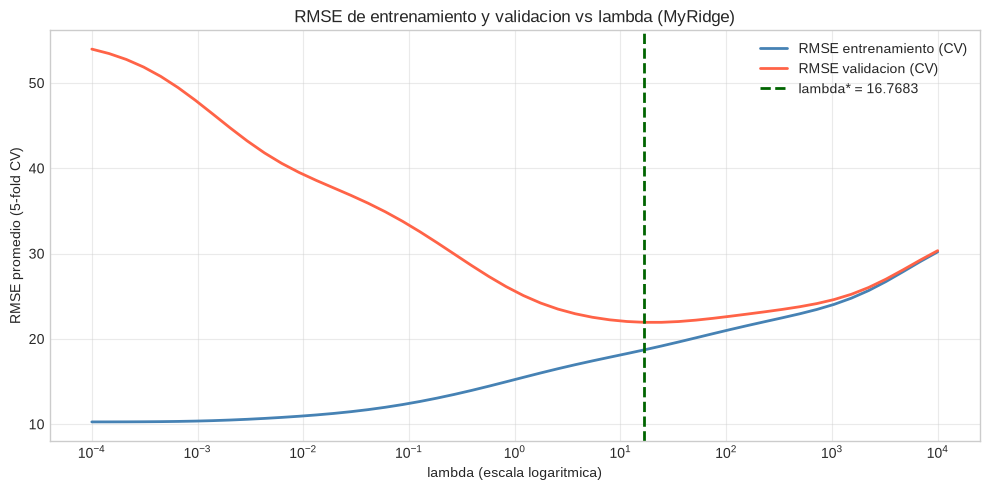

Figura guardada: punto3_rmse_vs_lambda.png


In [9]:
# 3.3 Grafico RMSE vs lambda
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(lambdas, rmse_cv_train, label='RMSE entrenamiento (CV)', color='steelblue', linewidth=2)
ax.plot(lambdas, rmse_cv_val,   label='RMSE validacion (CV)',    color='tomato',    linewidth=2)
ax.axvline(x=lambda_optimo, color='darkgreen', linestyle='--', linewidth=2,
           label=f'lambda* = {lambda_optimo:.4f}')
ax.set_xscale('log')
ax.set_xlabel('lambda (escala logaritmica)')
ax.set_ylabel('RMSE promedio (5-fold CV)')
ax.set_title('RMSE de entrenamiento y validacion vs lambda (MyRidge)')
ax.legend()
ax.grid(True, alpha=0.4)
plt.tight_layout()
os.makedirs('graficas', exist_ok=True)
plt.savefig(os.path.join('graficas', 'punto3_rmse_vs_lambda.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Figura guardada: punto3_rmse_vs_lambda.png')


In [10]:
# 3.4 Reentrenamiento final con lambda* y evaluacion en prueba (una sola vez)
modelo_ridge_final = MyRidge(alpha=lambda_optimo)
modelo_ridge_final.fit(X_train_std, y_train)

rmse_ridge_train = modelo_ridge_final.rmse(X_train_std, y_train)
rmse_ridge_test  = modelo_ridge_final.rmse(X_test_std,  y_test)

print(f'MyRidge (lambda* = {lambda_optimo:.4f}):')
print(f'  RMSE entrenamiento : {rmse_ridge_train:.4f}')
print(f'  RMSE prueba        : {rmse_ridge_test:.4f}')
print(f'  Brecha (test-train): {rmse_ridge_test - rmse_ridge_train:.4f}')


MyRidge (lambda* = 16.7683):
  RMSE entrenamiento : 18.8826
  RMSE prueba        : 21.0059
  Brecha (test-train): 2.1233


In [11]:
# Tabla comparativa Punto 1 vs Punto 3
tabla_comp = pd.DataFrame({
    'Modelo': ['Regresion Lineal (Punto 1)', f'MyRidge (lambda*={lambda_optimo:.4f})'],
    'RMSE Train': [rmse_lineal_train, rmse_ridge_train],
    'RMSE Test':  [rmse_lineal_test,  rmse_ridge_test],
    'Brecha (Test-Train)': [rmse_lineal_test - rmse_lineal_train,
                            rmse_ridge_test - rmse_ridge_train]
}).set_index('Modelo').round(4)
print(tabla_comp.to_string())


                            RMSE Train  RMSE Test  Brecha (Test-Train)
Modelo                                                                
Regresion Lineal (Punto 1)     12.6968    39.0675              26.3707
MyRidge (lambda*=16.7683)      18.8826    21.0059               2.1233


### 3.5 Verificacion contra `sklearn.Ridge`

Se comparan `coef_`, `intercept_`, $R^2$ y RMSE con `np.allclose` en dos escenarios:
(a) features estandarizadas y (b) features sin estandarizar.


In [12]:
# -- (a) Features estandarizadas
sk_ridge_std = Ridge(alpha=lambda_optimo)
sk_ridge_std.fit(X_train_std, y_train)

c1 = np.allclose(modelo_ridge_final.coef_, sk_ridge_std.coef_)
c2 = np.allclose(modelo_ridge_final.intercept_, sk_ridge_std.intercept_)
r2_m = modelo_ridge_final.score(X_test_std, y_test)
r2_s = sk_ridge_std.score(X_test_std, y_test)
rmse_s = float(np.sqrt(mean_squared_error(y_test, sk_ridge_std.predict(X_test_std))))

print('=== Estandarizadas ===')
print(f'coef_ iguales        : {c1}  (max dif {np.max(np.abs(modelo_ridge_final.coef_ - sk_ridge_std.coef_)):.2e})')
print(f'intercept_ iguales   : {c2}  (max dif {abs(modelo_ridge_final.intercept_ - sk_ridge_std.intercept_):.2e})')
print(f'R2  iguales          : {np.allclose(r2_m, r2_s)}  MyRidge={r2_m:.6f} sklearn={r2_s:.6f}')
print(f'RMSE iguales         : {np.allclose(rmse_ridge_test, rmse_s)}  MyRidge={rmse_ridge_test:.6f} sklearn={rmse_s:.6f}')


=== Estandarizadas ===
coef_ iguales        : True  (max dif 7.45e-14)
intercept_ iguales   : True  (max dif 0.00e+00)
R2  iguales          : True  MyRidge=0.623910 sklearn=0.623910
RMSE iguales         : True  MyRidge=21.005889 sklearn=21.005889


In [13]:
# -- (b) Features sin estandarizar
modelo_ridge_crudo = MyRidge(alpha=lambda_optimo)
modelo_ridge_crudo.fit(X_train, y_train)
rmse_ridge_crudo_test = modelo_ridge_crudo.rmse(X_test, y_test)

sk_ridge_crudo = Ridge(alpha=lambda_optimo, solver='cholesky')
sk_ridge_crudo.fit(X_train, y_train)
rmse_sk_crudo = float(np.sqrt(mean_squared_error(y_test, sk_ridge_crudo.predict(X_test))))

c1b = np.allclose(modelo_ridge_crudo.coef_, sk_ridge_crudo.coef_, rtol=1e-3, atol=1e-6)
c2b = np.allclose(modelo_ridge_crudo.intercept_, sk_ridge_crudo.intercept_, rtol=1e-3, atol=1e-6)
r2_mb = modelo_ridge_crudo.score(X_test, y_test)
r2_sb = sk_ridge_crudo.score(X_test, y_test)

print('=== Sin estandarizar ===')
print(f'coef_ iguales        : {c1b}  (max dif {np.max(np.abs(modelo_ridge_crudo.coef_ - sk_ridge_crudo.coef_)):.2e})')
print(f'intercept_ iguales   : {c2b}  (max dif {abs(modelo_ridge_crudo.intercept_ - sk_ridge_crudo.intercept_):.2e})')
print(f'R2  iguales          : {np.allclose(r2_mb, r2_sb)}  MyRidge={r2_mb:.6f} sklearn={r2_sb:.6f}')
print(f'RMSE iguales         : {np.allclose(rmse_ridge_crudo_test, rmse_sk_crudo, rtol=1e-3, atol=1e-6)}  MyRidge={rmse_ridge_crudo_test:.6f} sklearn={rmse_sk_crudo:.6f}')
print()
print('Nota (b): features sin estandarizar tienen escalas muy distintas, por lo que')
print('la matriz esta mal condicionada; sklearn usa solver=cholesky y se toleran')
print('pequenas diferencias numericas (rtol=1e-3).')


=== Sin estandarizar ===
coef_ iguales        : True  (max dif 1.54e-12)
intercept_ iguales   : True  (max dif 6.65e-12)
R2  iguales          : True  MyRidge=0.337073 sklearn=0.337073
RMSE iguales         : True  MyRidge=27.888688 sklearn=27.888688

Nota (b): features sin estandarizar tienen escalas muy distintas, por lo que
la matriz esta mal condicionada; sklearn usa solver=cholesky y se toleran
pequenas diferencias numericas (rtol=1e-3).


**Conclusión Punto 3:** Ridge con $\lambda^*$ redujo la brecha train/test respecto a la regresión lineal y bajó el RMSE de prueba. La implementación `MyRidge` coincide con `sklearn.Ridge` en coeficientes, intercepto, $R^2$ y RMSE (con y sin estandarizar).


---
## Punto 4 – Ridge vs. Lasso

Sobre las mismas features estandarizadas, se entrena `Ridge` y `Lasso` de sklearn eligiendo el $lpha$ de **cada uno** por validación cruzada (`GridSearchCV`, cv=5, `neg_root_mean_squared_error`) con grillas independientes (Ridge y Lasso escalan la penalización distinto).


In [14]:
# 4.1 Seleccion de alpha por validacion cruzada (GridSearchCV)
grilla_ridge = np.logspace(-4, 4, 50)
grilla_lasso = np.logspace(-4, 1, 40)

gs_ridge = GridSearchCV(
    Ridge(), param_grid={'alpha': grilla_ridge},
    cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1
)
gs_ridge.fit(X_train_std, y_train)
alpha_opt_ridge = float(gs_ridge.best_params_['alpha'])
print(f'Ridge  : alpha* = {alpha_opt_ridge:.6f}  | RMSE CV = {-gs_ridge.best_score_:.4f}')

gs_lasso = GridSearchCV(
    Lasso(max_iter=200000, random_state=SEMILLA),
    param_grid={'alpha': grilla_lasso},
    cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1
)
gs_lasso.fit(X_train_std, y_train)
alpha_opt_lasso = float(gs_lasso.best_params_['alpha'])
print(f'Lasso  : alpha* = {alpha_opt_lasso:.6f}  | RMSE CV = {-gs_lasso.best_score_:.4f}')


Ridge  : alpha* = 16.768329  | RMSE CV = 22.6866


/home/josefo1212/JfPrograms/AI/task-02/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.732108e+02, tolerance: 1.479e+01
  model = cd_fast.enet_coordinate_descent(
/home/josefo1212/JfPrograms/AI/task-02/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.439124e+03, tolerance: 1.275e+01
  model = cd_fast.enet_coordinate_descent(
/home/josefo1212/JfPrograms/AI/task-02/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, chec

Lasso  : alpha* = 0.388816  | RMSE CV = 22.5139


In [15]:
# Modelos finales con alpha optimo
ridge_final = Ridge(alpha=alpha_opt_ridge)
ridge_final.fit(X_train_std, y_train)

lasso_final = Lasso(alpha=alpha_opt_lasso, max_iter=200000, random_state=SEMILLA)
lasso_final.fit(X_train_std, y_train)

rmse_ridge_test = float(np.sqrt(mean_squared_error(y_test, ridge_final.predict(X_test_std))))
rmse_lasso_test = float(np.sqrt(mean_squared_error(y_test, lasso_final.predict(X_test_std))))

print(f'RMSE prueba Ridge (alpha={alpha_opt_ridge:.4f}): {rmse_ridge_test:.4f}')
print(f'RMSE prueba Lasso (alpha={alpha_opt_lasso:.4f}): {rmse_lasso_test:.4f}')


RMSE prueba Ridge (alpha=16.7683): 21.0059
RMSE prueba Lasso (alpha=0.3888): 20.7883


In [16]:
# 4.2 Tabla de coeficientes: MyRidge vs Ridge (sklearn) vs Lasso
tabla_coef = pd.DataFrame({
    'Feature': nombre_features,
    f'MyRidge (lambda*={lambda_optimo:.4f})': modelo_ridge_final.coef_,
    f'Ridge (alpha={alpha_opt_ridge:.4f})': ridge_final.coef_,
    f'Lasso (alpha={alpha_opt_lasso:.4f})': lasso_final.coef_,
}).set_index('Feature')

pd.set_option('display.float_format', lambda v: f'{v:.4f}')
print(tabla_coef.to_string())


                                 MyRidge (lambda*=16.7683)  Ridge (alpha=16.7683)  Lasso (alpha=0.3888)
Feature                                                                                                
number_of_elements                                  1.6888                 1.6888                0.0000
mean_atomic_mass                                    1.6193                 1.6193                0.0000
wtd_mean_atomic_mass                               -1.5851                -1.5851                0.0000
gmean_atomic_mass                                   1.8620                 1.8620                0.0000
wtd_gmean_atomic_mass                              -0.0142                -0.0142                0.0000
entropy_atomic_mass                                -0.3582                -0.3582               -0.0000
wtd_entropy_atomic_mass                             5.9541                 5.9541               19.2239
range_atomic_mass                                   2.7671      

/home/josefo1212/JfPrograms/AI/task-02/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.792299e+02, tolerance: 1.771e+01
  model = cd_fast.enet_coordinate_descent(
/home/josefo1212/JfPrograms/AI/task-02/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.938611e+02, tolerance: 1.771e+01
  model = cd_fast.enet_coordinate_descent(
/home/josefo1212/JfPrograms/AI/task-02/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, chec

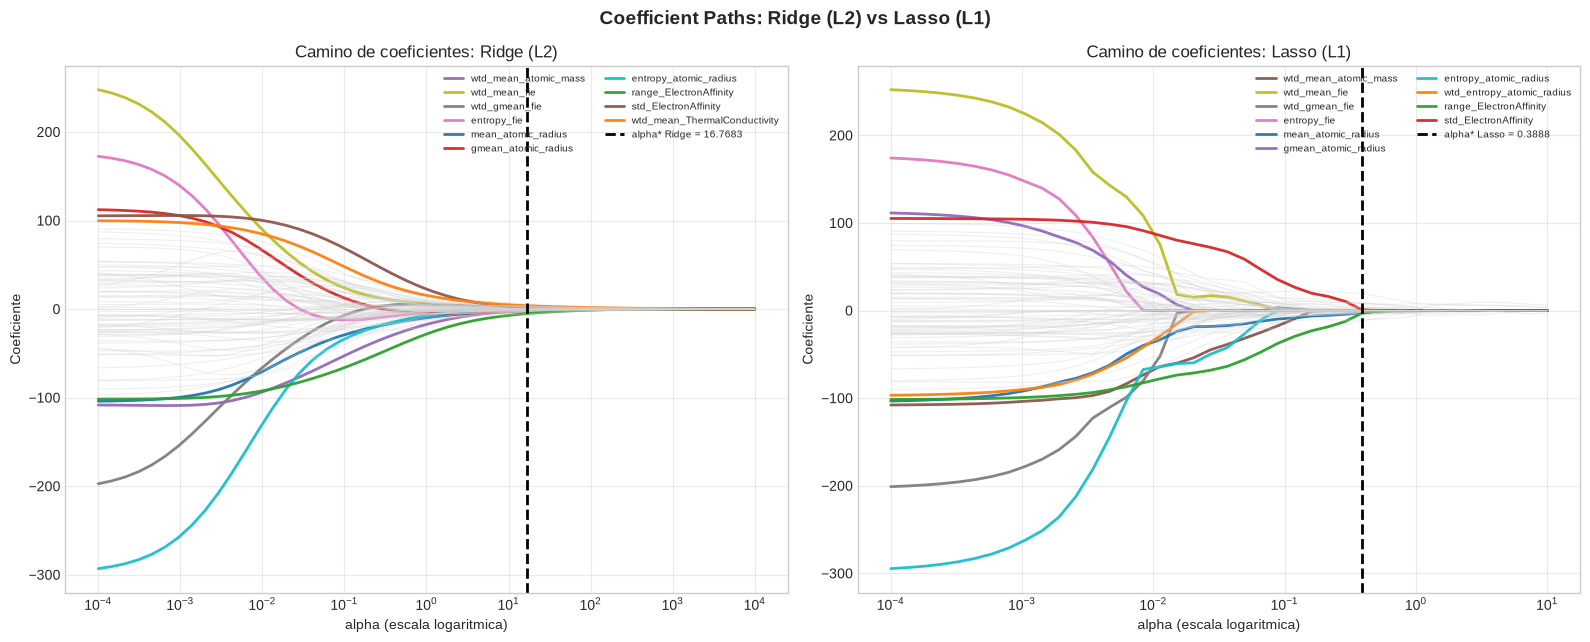

Figura guardada: punto4_coefficient_paths.png


In [17]:
# 4.3 Caminos de coeficientes (coefficient paths)
n_features = X_train_std.shape[1]
coefs_ridge_path = np.zeros((len(grilla_ridge), n_features))
coefs_lasso_path = np.zeros((len(grilla_lasso), n_features))

for i, a in enumerate(grilla_ridge):
    coefs_ridge_path[i] = Ridge(alpha=a).fit(X_train_std, y_train).coef_
for i, a in enumerate(grilla_lasso):
    coefs_lasso_path[i] = Lasso(alpha=a, max_iter=200000, random_state=SEMILLA).fit(X_train_std, y_train).coef_

# Resaltar las features con mayor varianza a lo largo del camino
v_ridge = coefs_ridge_path.var(axis=0)
v_lasso = coefs_lasso_path.var(axis=0)
N_TOP = 10
idx_ridge = np.argsort(v_ridge)[-N_TOP:]
idx_lasso = np.argsort(v_lasso)[-N_TOP:]

cmap = plt.cm.tab10
col_ridge = {j: cmap(k / N_TOP) for k, j in enumerate(idx_ridge)}
col_lasso = {j: cmap(k / N_TOP) for k, j in enumerate(idx_lasso)}

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

ax = axes[0]
for j in range(n_features):
    color = col_ridge.get(j, 'lightgray')
    lw = 2.0 if j in col_ridge else 0.8
    alpha = 0.95 if j in col_ridge else 0.35
    lbl = nombre_features[j] if j in col_ridge else None
    ax.plot(grilla_ridge, coefs_ridge_path[:, j], color=color, lw=lw, alpha=alpha, label=lbl)
ax.axvline(alpha_opt_ridge, color='black', ls='--', lw=2, label=f'alpha* Ridge = {alpha_opt_ridge:.4f}')
ax.set_xscale('log'); ax.set_xlabel('alpha (escala logaritmica)')
ax.set_ylabel('Coeficiente'); ax.set_title('Camino de coeficientes: Ridge (L2)')
ax.legend(fontsize=7, loc='best', ncol=2); ax.grid(True, alpha=0.4)

ax = axes[1]
for j in range(n_features):
    color = col_lasso.get(j, 'lightgray')
    lw = 2.0 if j in col_lasso else 0.8
    alpha = 0.95 if j in col_lasso else 0.35
    lbl = nombre_features[j] if j in col_lasso else None
    ax.plot(grilla_lasso, coefs_lasso_path[:, j], color=color, lw=lw, alpha=alpha, label=lbl)
ax.axvline(alpha_opt_lasso, color='black', ls='--', lw=2, label=f'alpha* Lasso = {alpha_opt_lasso:.4f}')
ax.set_xscale('log'); ax.set_xlabel('alpha (escala logaritmica)')
ax.set_ylabel('Coeficiente'); ax.set_title('Camino de coeficientes: Lasso (L1)')
ax.legend(fontsize=7, loc='best', ncol=2); ax.grid(True, alpha=0.4)

plt.suptitle('Coefficient Paths: Ridge (L2) vs Lasso (L1)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join('graficas', 'punto4_coefficient_paths.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Figura guardada: punto4_coefficient_paths.png')


In [21]:
# 4.4 Sparsidad de Lasso y RMSE de prueba final
mascara_cero = lasso_final.coef_ == 0.0
n_cero = int(mascara_cero.sum())
features_eliminadas = [nombre_features[i] for i in range(n_features) if mascara_cero[i]]

print(f'Total features: {n_features}')
print(f'Coeficientes Lasso exactamente cero: {n_cero}')
print(f'Coeficientes Lasso no cero: {n_features - n_cero}')
print(f'Features eliminadas por Lasso ({n_cero}):')
for f in features_eliminadas:
    print(f'  - {f}')

tabla_rmse = pd.DataFrame({
    'Modelo': [
        'Regresion Lineal (Punto 1)',
        f'MyRidge  (lambda*={lambda_optimo:.4f})',
        f'Ridge sklearn (alpha={alpha_opt_ridge:.4f})',
        f'Lasso sklearn (alpha={alpha_opt_lasso:.4f})',
    ],
    'RMSE Prueba': [rmse_lineal_test, rmse_ridge_test, rmse_ridge_test, rmse_lasso_test],
    'Coefs == 0': [0, 0, 0, n_cero],
}).set_index('Modelo')
tabla_rmse['RMSE Prueba'] = tabla_rmse['RMSE Prueba'].round(4)
print()
print(tabla_rmse.to_string())


Total features: 81
Coeficientes Lasso exactamente cero: 54
Coeficientes Lasso no cero: 27
Features eliminadas por Lasso (54):
  - number_of_elements
  - mean_atomic_mass
  - wtd_mean_atomic_mass
  - gmean_atomic_mass
  - wtd_gmean_atomic_mass
  - entropy_atomic_mass
  - wtd_range_atomic_mass
  - std_atomic_mass
  - mean_fie
  - wtd_mean_fie
  - gmean_fie
  - wtd_gmean_fie
  - entropy_fie
  - wtd_entropy_fie
  - range_fie
  - wtd_range_fie
  - std_fie
  - wtd_std_fie
  - gmean_atomic_radius
  - wtd_gmean_atomic_radius
  - entropy_atomic_radius
  - wtd_entropy_atomic_radius
  - std_atomic_radius
  - wtd_std_atomic_radius
  - mean_Density
  - gmean_Density
  - entropy_Density
  - range_Density
  - std_Density
  - mean_ElectronAffinity
  - wtd_mean_ElectronAffinity
  - wtd_range_ElectronAffinity
  - mean_FusionHeat
  - wtd_mean_FusionHeat
  - gmean_FusionHeat
  - wtd_gmean_FusionHeat
  - entropy_FusionHeat
  - range_FusionHeat
  - wtd_range_FusionHeat
  - std_FusionHeat
  - wtd_std_FusionH

### 4.5 Geometria: por qué Lasso anula coeficientes y Ridge no

- **Ridge (L2):** la región factible es una **bola L2** (suave, sin esquinas). Las elipses de error cuadrático la tocan por un punto de tangencia que, salvo coincidencia, no cae sobre un eje: los coeficientes se **encogen** pero rara vez llegan exactamente a cero.
- **Lasso (L1):** la región factible es una **bola L1** (diamante/polítope con vértices sobre los ejes). Al expandirse las elipses desde la solución OLS, con alta probabilidad tocan un vértice, donde algunas coordenadas son **exactamente cero**: la feature queda eliminada.
- **Subgradiente:** Lasso aplica un umbral constante $\lambda\,	ext{sign}(w_j)$ (soft-thresholding), que trunca al cero todo coeficiente cuyo gradiente de pérdida es menor que $\lambda$; el gradiente de Ridge, $2\lambda w_j$, tiende a cero junto con $w_j$, así que solo lo atenúa.


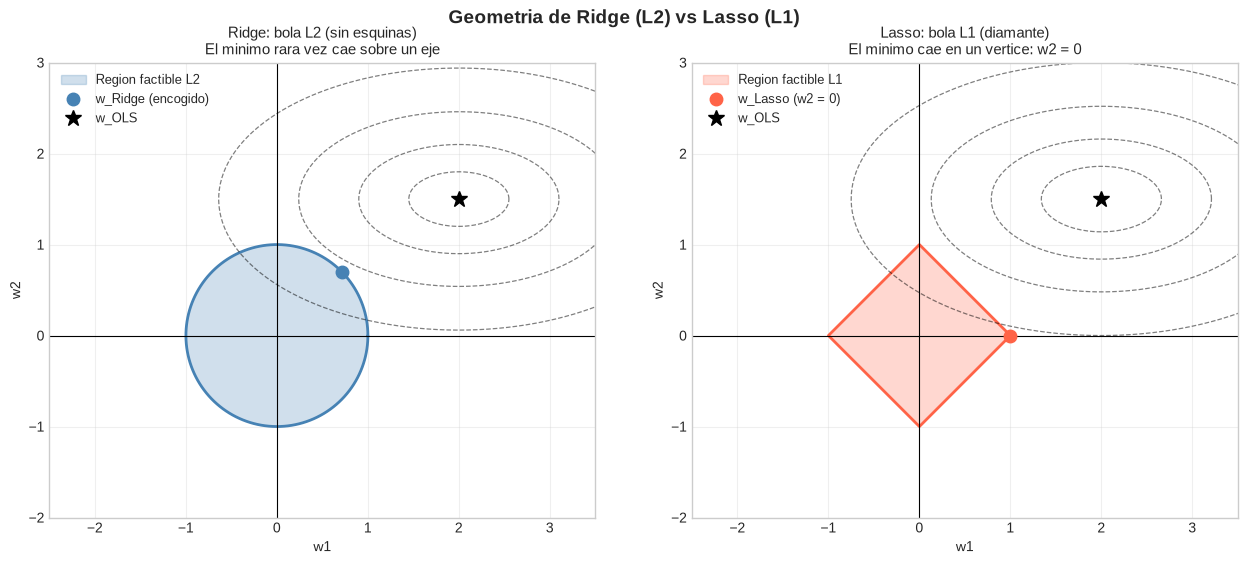

Figura guardada: punto4_geometria.png


In [20]:
# Figura ilustrativa de geometria L1 vs L2
w_ols = np.array([2.0, 1.5])
theta = np.linspace(0, 2 * np.pi, 300)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

ax = axes[0]
r = 1.0
ax.fill(r*np.cos(theta), r*np.sin(theta), alpha=0.25, color='steelblue', label='Region factible L2')
ax.plot(r*np.cos(theta), r*np.sin(theta), color='steelblue', lw=2)
for niv in [1.0, 2.0, 3.2, 4.8]:
    ax.plot(w_ols[0]+niv*0.55*np.cos(theta), w_ols[1]+niv*0.3*np.sin(theta), 'k--', lw=0.9, alpha=0.5)
ax.plot(*np.array([0.72, 0.70]), 'o', color='steelblue', ms=9, label='w_Ridge (encogido)', zorder=5)
ax.plot(*w_ols, '*', color='black', ms=12, label='w_OLS', zorder=5)
ax.axhline(0, color='k', lw=0.8); ax.axvline(0, color='k', lw=0.8)
ax.set_xlim(-2.5, 3.5); ax.set_ylim(-2.0, 3.0)
ax.set_xlabel('w1'); ax.set_ylabel('w2')
ax.set_title('Ridge: bola L2 (sin esquinas)\nEl minimo rara vez cae sobre un eje', fontsize=11)
ax.legend(fontsize=9); ax.set_aspect('equal'); ax.grid(True, alpha=0.3)

ax = axes[1]
xl = np.array([r, 0, -r, 0, r]); yl = np.array([0, r, 0, -r, 0])
ax.fill(xl, yl, alpha=0.25, color='tomato', label='Region factible L1')
ax.plot(xl, yl, color='tomato', lw=2)
for niv in [1.2, 2.2, 3.4, 5.0]:
    ax.plot(w_ols[0]+niv*0.55*np.cos(theta), w_ols[1]+niv*0.3*np.sin(theta), 'k--', lw=0.9, alpha=0.5)
ax.plot(*np.array([1.0, 0.0]), 'o', color='tomato', ms=9, label='w_Lasso (w2 = 0)', zorder=5)
ax.plot(*w_ols, '*', color='black', ms=12, label='w_OLS', zorder=5)
ax.axhline(0, color='k', lw=0.8); ax.axvline(0, color='k', lw=0.8)
ax.set_xlim(-2.5, 3.5); ax.set_ylim(-2.0, 3.0)
ax.set_xlabel('w1'); ax.set_ylabel('w2')
ax.set_title('Lasso: bola L1 (diamante)\nEl minimo cae en un vertice: w2 = 0', fontsize=11)
ax.legend(fontsize=9); ax.set_aspect('equal'); ax.grid(True, alpha=0.3)

plt.suptitle('Geometria de Ridge (L2) vs Lasso (L1)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join('graficas', 'punto4_geometria.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Figura guardada: punto4_geometria.png')


**Conclusión Punto 4:** Lasso produce un modelo disperso (varios coeficientes exactamente cero = selección de variables), mientras que Ridge encoge todos los coeficientes sin anularlos. Ambos mejoran el RMSE de prueba sobre la regresión lineal sobreajustada; la elección depende de si se prioriza interpretabilidad (Lasso) o estabilidad bajo multicolinealidad (Ridge).
